# Saudi Used-Car Price Predictor

**Goal:** estimate the price (SAR) of a used car from its make, model, year, mileage, engine size, options, gearbox, fuel and region.

**Plan**
1. Load and clean the data
2. Baseline: compare Random Forest and XGBoost with 5-fold cross-validation
3. Improve accuracy: fix mileage typos, tune XGBoost, add CatBoost and a neural network, blend (before/after table)
4. Make *out-of-fold* predictions (each car is predicted by a model that never saw it) and save `predictions.csv`
5. Charts: feature importance and actual vs predicted
6. Train the final model on all data and save it
7. Live demo: type in a car, get a price

## 1. Load and clean the data

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from carmodel import (SEED, CATEGORICAL, NUMERIC, FEATURES, load_data, fix_mileage,
                      make_xgb, make_mlp, BlendRegressor)   # helpers live in carmodel.py

df = load_data("cars_export.csv")   # also turns "$95000.00" into 95000.0 (values are SAR)

print(df.shape, "| missing values:", int(df.isna().sum().sum()))
print("Cars with mileage under 1,000 km (probably typed in thousands):", int((df.Mileage < 1000).sum()))
df.head()

(4286, 13) | missing values: 0
Cars with mileage under 1,000 km (probably typed in thousands): 352


,CarID,MakeName,Country,Model,Year,Age,Mileage,EngineSize,FuelType,GearType,Options,RegionName,Price
0,1,Toyota,Japan,4Runner,2018,8,115150,6.1,Gas,Automatic,Full,Jeddah,95000.0
1,2,Toyota,Japan,Aurion,2009,17,373000,3.5,Gas,Automatic,Full,Riyadh,33500.0
2,3,Toyota,Japan,Aurion,2010,16,342000,3.5,Gas,Automatic,Standard,Jubail,30000.0
3,4,Toyota,Japan,Aurion,2014,12,245,1.0,Gas,Automatic,Standard,Makkah,55000.0
4,5,Toyota,Japan,Aurion,2015,11,300,2.6,Gas,Automatic,Semi Full,Jazan,50000.0


In [2]:
df[["Year", "Mileage", "EngineSize", "Price"]].describe().round(1)

,Year,Mileage,EngineSize,Price
count,4286.0,4286.0,4286.0,4286.0
mean,2014.8,128816.7,3.2,76677.2
std,4.9,104379.2,1.5,68262.7
min,1980.0,100.0,1.0,5000.0
25%,2013.0,52000.0,2.0,36000.0
50%,2016.0,105533.5,2.7,58000.0
75%,2018.0,185000.0,4.0,92000.0
max,2021.0,500000.0,9.0,1150000.0


## 2. Baseline: compare models with 5-fold cross-validation

Categorical columns are one-hot encoded. We try each model on the plain price and on `log(Price)`.
`cross_val_predict` gives **out-of-fold** predictions: every car is predicted by a model trained on the *other* folds, so the scores are honest.

In [3]:
def make_model(regressor, log_target):
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough")
    pipe = Pipeline([("prep", pre), ("reg", regressor)])
    if log_target:
        return TransformedTargetRegressor(pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

def rf():  return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
def xgb(): return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
                               colsample_bytree=0.8, n_jobs=-1, random_state=SEED)

candidates = {"RandomForest": rf, "RandomForest (log price)": rf,
              "XGBoost": xgb, "XGBoost (log price)": xgb}

X, y = df[FEATURES], df["Price"]
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

rows, oof = [], {}
for name, factory in candidates.items():
    pred = cross_val_predict(make_model(factory(), "log" in name), X, y, cv=cv)
    mae = [mean_absolute_error(y.iloc[te], pred[te]) for _, te in cv.split(X)]
    r2 = [r2_score(y.iloc[te], pred[te]) for _, te in cv.split(X)]
    rows.append({"Model": name, "MAE (SAR)": np.mean(mae), "MAE std": np.std(mae),
                 "R2": np.mean(r2), "R2 std": np.std(r2)})
    oof[name] = pred

results = pd.DataFrame(rows).set_index("Model").round(3)
best = results["MAE (SAR)"].idxmin()
print("Best model by MAE:", best)
results

Best model by MAE: XGBoost


,MAE (SAR),MAE std,R2,R2 std
Model,,,,
RandomForest,11141.856,970.445,0.893,0.051
RandomForest (log price),11674.541,943.846,0.869,0.045
XGBoost,9988.477,653.011,0.928,0.016
XGBoost (log price),10222.850,589.270,0.908,0.016


## 3. Can we do better?

Ideas tried, each scored with the **same 5-fold CV**:
- **Fix mileage typos**: 352 cars (8%) have mileage like 230, clearly thousands of km. Multiply by 1,000.
- **Tune XGBoost**: deeper trees (depth 8), more of them, slower learning rate.
- **CatBoost** on log(price): handles categories like Model natively.
- **Neural network** (one hidden layer of 64 neurons, log price): weaker alone than XGBoost, but it makes *different* mistakes.
- **Blend**: average the models, since their mistakes partly cancel out.

Other ideas were tried and did *not* help: extra features (miles per year, age squared), grouping rare models into "Other", a stronger-regularised XGBoost, and an MAE-loss XGBoost.

In [4]:
df_fixed = fix_mileage(df)
Xf, yf = df_fixed[FEATURES], df_fixed["Price"]

def score(name, pred, store):
    err = np.abs(yf - pred)
    store.append({"Step": name, "MAE (SAR)": round(mean_absolute_error(yf, pred)),
                  "R2": round(r2_score(yf, pred), 3), "Median miss (SAR)": round(err.median()),
                  "Within 10k SAR": f"{(err <= 10000).mean():.0%}"})

steps, oof2 = [], {}
oof2["XGBoost baseline"] = oof["XGBoost"]
score("1. XGBoost baseline (before)", oof2["XGBoost baseline"], steps)

oof2["fix"] = cross_val_predict(make_xgb(), Xf, yf, cv=cv)
score("2. + fixed mileage", oof2["fix"], steps)

oof2["tuned"] = cross_val_predict(make_xgb(max_depth=8, n_estimators=800, learning_rate=0.03), Xf, yf, cv=cv)
score("3. + tuned XGBoost", oof2["tuned"], steps)

cat = np.zeros(len(Xf))
for tr, te in cv.split(Xf):
    m = CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=6, verbose=0, random_seed=SEED,
                          cat_features=CATEGORICAL, thread_count=-1)
    m.fit(Xf.iloc[tr], np.log1p(yf.iloc[tr]))
    cat[te] = np.expm1(m.predict(Xf.iloc[te]))
oof2["cat"] = cat
score("   (CatBoost alone, log price)", cat, steps)

oof2["blend2"] = 0.5 * oof2["tuned"] + 0.5 * cat
score("4. + blend XGBoost & CatBoost", oof2["blend2"], steps)

oof2["nn"] = cross_val_predict(make_mlp(), Xf, yf, cv=cv)
score("   (neural network alone, log price)", oof2["nn"], steps)

oof2["blend"] = (oof2["tuned"] + cat + oof2["nn"]) / 3
score("5. + neural network in the blend (final)", oof2["blend"], steps)
pd.DataFrame(steps).set_index("Step")

,MAE (SAR),R2,Median miss (SAR),Within 10k SAR
Step,,,,
1. XGBoost baseline (before),9989,0.926,5865,70%
2. + fixed mileage,9949,0.922,5848,70%
3. + tuned XGBoost,9814,0.918,5507,71%
"(CatBoost alone, log price)",10136,0.874,5441,71%
4. + blend XGBoost & CatBoost,9574,0.908,5375,71%
"(neural network alone, log price)",10329,0.910,5675,69%
5. + neural network in the blend (final),9347,0.919,5276,72%


## 4. Out-of-fold predictions -> `predictions.csv`

Only the final (blended) model's out-of-fold predictions are saved: two columns, `CarID` and `PredictedPrice` (whole SAR).

In [5]:
pred = np.round(oof2["blend"]).astype(int)
y = yf
pd.DataFrame({"CarID": df["CarID"], "PredictedPrice": pred}).to_csv("predictions.csv", index=False)

err = np.abs(y - pred)
print(f"Median miss: {err.median():,.0f} SAR | within 10,000 SAR: {(err <= 10000).mean():.0%} | within 20,000 SAR: {(err <= 20000).mean():.0%}")
pd.read_csv("predictions.csv").head()

Median miss: 5,276 SAR | within 10,000 SAR: 72% | within 20,000 SAR: 90%


,CarID,PredictedPrice
0,1,96434
1,2,30322
2,3,29293
3,4,31520
4,5,44721


## 5. Charts for the presentation

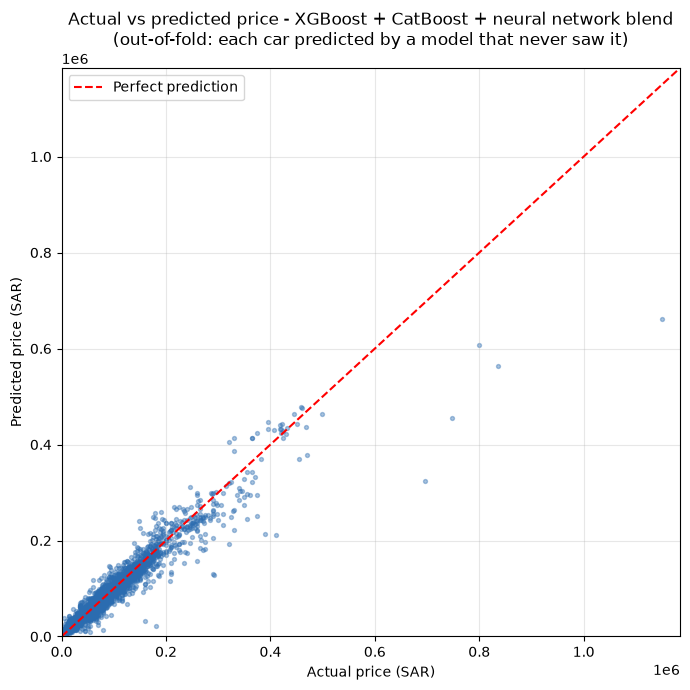

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y, pred, s=8, alpha=0.4, color="#2b6cb0")
lim = max(y.max(), pred.max()) * 1.03
ax.plot([0, lim], [0, lim], "r--", lw=1.5, label="Perfect prediction")
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Actual price (SAR)", ylabel="Predicted price (SAR)",
       title=f"Actual vs predicted price - XGBoost + CatBoost + neural network blend\n(out-of-fold: each car predicted by a model that never saw it)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("actual_vs_predicted.png", dpi=150); plt.show()

**Feature importance** uses *permutation importance on held-out folds*: scramble one column and see how much the error grows. (The model's built-in importances are misleading with one-hot columns.)

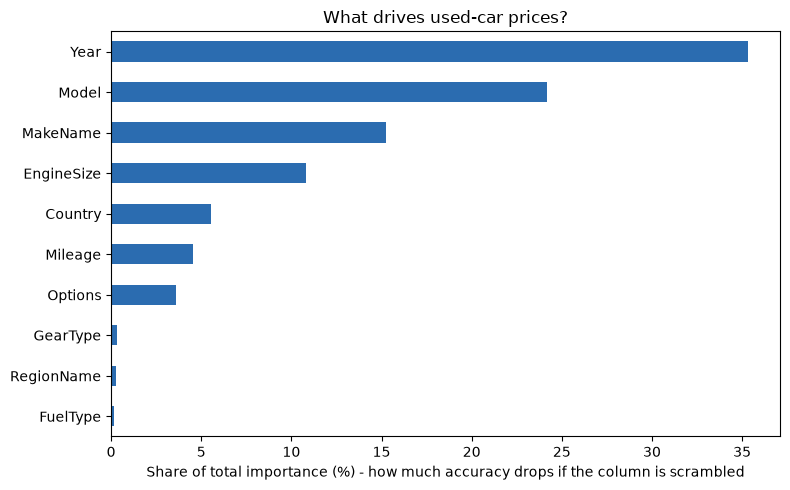

Year          35.3
Model         24.2
MakeName      15.3
EngineSize    10.8
Country        5.5
Mileage        4.5
Options        3.6
GearType       0.3
RegionName     0.3
FuelType       0.2
dtype: float64

In [7]:
rng = np.random.RandomState(SEED)
inc = {c: [] for c in FEATURES}
for tr, te in cv.split(X):
    m = BlendRegressor().fit(Xf.iloc[tr], yf.iloc[tr])
    Xte, yte = Xf.iloc[te], yf.iloc[te]
    base = mean_absolute_error(yte, m.predict(Xte))
    for c in FEATURES:
        for _ in range(3):
            Xp = Xte.copy(); Xp[c] = rng.permutation(Xp[c].values)
            inc[c].append(mean_absolute_error(yte, m.predict(Xp)) - base)
imp = pd.Series({c: np.mean(v) for c, v in inc.items()}).clip(lower=0)
imp = (imp / imp.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
imp.mul(100).plot.barh(ax=ax, color="#2b6cb0")
ax.set(xlabel="Share of total importance (%) - how much accuracy drops if the column is scrambled",
       title="What drives used-car prices?")
fig.tight_layout(); fig.savefig("feature_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).mul(100).round(1)

## 6. Train the final model on all data and save it

In [8]:
final = BlendRegressor().fit(Xf, yf)
meta = {
    "makes": {m: sorted(g["Model"].unique().tolist()) for m, g in df.groupby("MakeName")},
    "make_country": df.groupby("MakeName")["Country"].agg(lambda s: s.mode()[0]).to_dict(),
    "regions": df["RegionName"].value_counts().index.tolist(),
    "fuels": df["FuelType"].value_counts().index.tolist(),
    "gears": df["GearType"].value_counts().index.tolist(),
    "options": ["Standard", "Semi Full", "Full"],
    "year_range": [int(df["Year"].min()), int(df["Year"].max())],
    "defaults": {"FuelType": "Gas", "GearType": "Automatic", "Options": "Standard"},
    "model_name": "XGBoost + CatBoost + neural network blend",
}
joblib.dump({"model": final, "meta": meta}, "model.joblib")
json.dump({"final_model": "XGBoost + CatBoost + neural network blend", "baseline_cv": results.reset_index().to_dict("records"),
           "improvement_steps": steps,
           "importance_pct": {k: round(v * 100, 2) for k, v in imp.sort_values(ascending=False).items()}},
          open("metrics.json", "w"), indent=2)
print("Saved model.joblib and metrics.json")

Saved model.joblib and metrics.json


## 7. Live demo

Quick check with a fixed car, then the interactive version (run the last cell and answer the questions).

In [9]:
def estimate(make, model, year, mileage, region="Riyadh", engine=2.0,
             gear="Automatic", fuel="Gas", options="Standard"):
    car = pd.DataFrame([{"MakeName": make, "Country": meta["make_country"][make], "Model": model,
                         "FuelType": fuel, "GearType": gear, "Options": options, "RegionName": region,
                         "Year": year, "Mileage": mileage, "EngineSize": engine}])
    return float(final.predict(car)[0])

p = estimate("Toyota", "4Runner", 2018, 115150, "Jeddah", 6.1, options="Full")
print(f"2018 Toyota 4Runner, 115,150 km, Jeddah: about {round(p, -2):,.0f} SAR")

2018 Toyota 4Runner, 115,150 km, Jeddah: about 104,100 SAR


In [10]:
def pick(prompt, options, default=None):
    lookup = {o.lower(): o for o in options}
    while True:
        a = input(f"{prompt}" + (f" [Enter = {default}]" if default else "") + ": ").strip()
        if not a and default: return default
        if a.lower() in lookup: return lookup[a.lower()]
        print("  Please choose one of:", ", ".join(options))

def number(prompt, lo, hi, cast=int, default=None):
    while True:
        a = input(f"{prompt}" + (f" [Enter = {default}]" if default is not None else "") + ": ").strip().replace(",", "")
        if not a and default is not None: return default
        try:
            v = cast(a)
            if lo <= v <= hi: return v
        except ValueError:
            pass
        print(f"  Please enter a number between {lo:,} and {hi:,}.")

def ask_and_predict():
    print("=== Saudi Used-Car Price Estimator ===")
    makes = sorted(meta["makes"]); print("Makes:", ", ".join(makes))
    make = pick("Make", makes)
    models = meta["makes"][make]; print(f"{make} models:", ", ".join(models))
    model = pick("Model", models)
    year = number("Year", *meta["year_range"])
    mileage = number("Mileage (km)", 0, 1_000_000)
    print("Regions:", ", ".join(meta["regions"]))
    region = pick("Region", meta["regions"], default=meta["regions"][0])
    engine = number("Engine size (litres, e.g. 2.5)", 0.5, 10.0, float, default=2.0)
    gear = pick("Gearbox (Automatic/Manual)", meta["gears"], default="Automatic")
    fuel = pick("Fuel (Gas/Diesel/Hybrid)", meta["fuels"], default="Gas")
    options = pick("Options (Standard/Semi Full/Full)", meta["options"], default="Standard")
    p = estimate(make, model, year, mileage, region, engine, gear, fuel, options)
    print(f"\n>>> Estimated price for a {year} {make} {model}: {round(p, -2):,.0f} SAR  (typical error about +/- 10,000 SAR)")

In [ ]:
ask_and_predict()   # run this cell for the live demo; run it again for another car